# 04 — Szövegelemzés és klasszikus modellek a BERT-címkéken / Text analysis and classical models on the BERT labels

HU: A konzulens által jónak ítélt TF-IDF-alapú szóelemzés most a **szövegből származó** címkéken fut (`label_final`),
nem a pontszám-vágáson. Utána a klasszikus modellek (NB, LogReg, SVM) megtanulják a BERT-címkéket: gyors, értelmezhető
"tanítvány" modellek, amelyek CPU-n is címkéznek.

EN: The TF-IDF word analysis (approved by the supervisor) now runs on the **text-derived** labels (`label_final`),
not on the score cut. Then the classical models (NB, LogReg, SVM) learn the BERT labels: fast, interpretable
"student" models that label on a CPU too.

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import descriptives as ds
from src import text_analysis as ta
from src import aspects as asp
from src import models_classical as mc
from src import label_validation as lv
from src import pipeline
import time

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

LABEL_COL = "label_final"
data = ds.prepare_star_rating(dl.read_frame(pipeline.LABELLED))
print(f"{len(data):,} reviews | label: {LABEL_COL}")
display(data[LABEL_COL].value_counts(normalize=True).round(3).to_frame("share"))

20,000 reviews | label: label_final


,share
label_final,
positive,0.790
neutral,0.154
negative,0.056


## 1. Megkülönböztető kifejezések / Distinctive terms

16:05:06 | INFO    | src.text_analysis | Vocabulary: 3083 terms (1-2-gram)
16:05:06 | INFO    | src.evaluation | Table saved: 04_distinctive_terms.csv
16:05:07 | INFO    | src.evaluation | Figure saved: 04_distinctive_terms.png


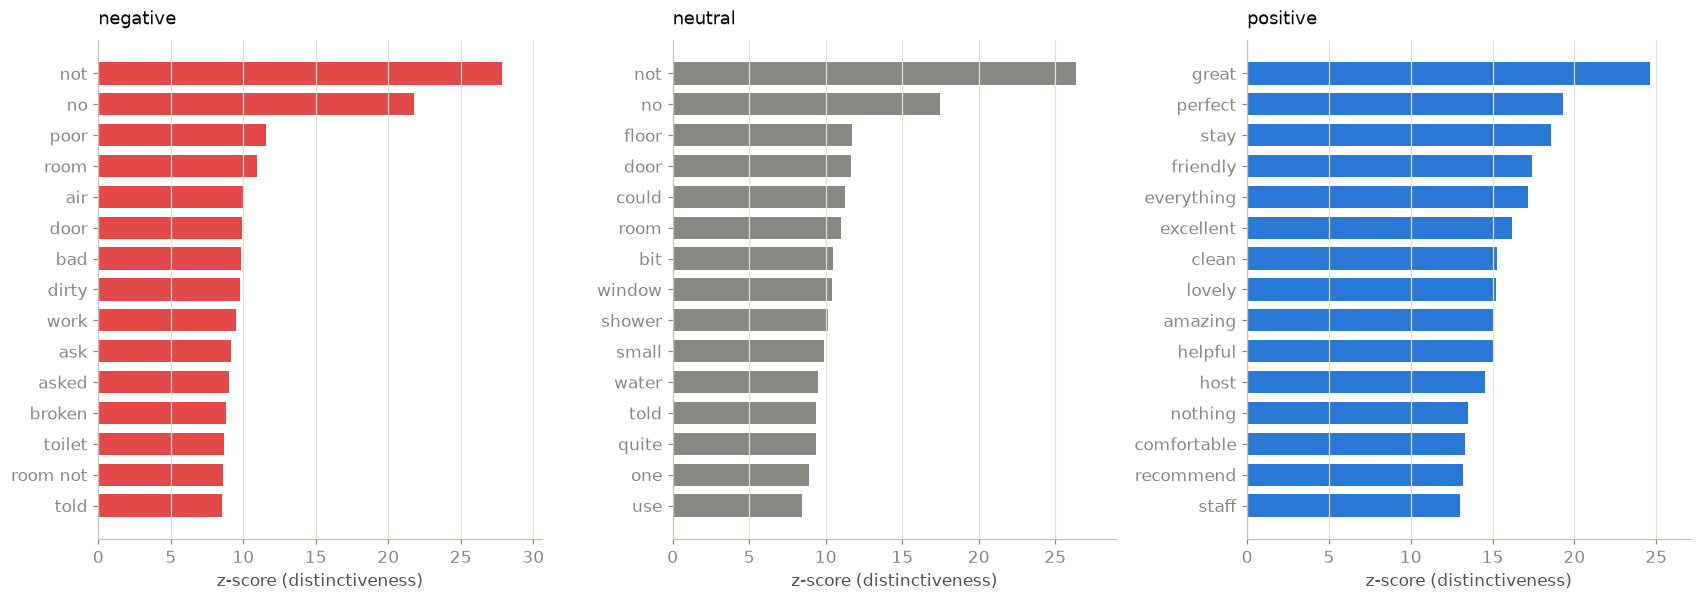

16:05:10 | INFO    | src.text_analysis | Vocabulary: 1628 terms (2-3-gram)
16:05:10 | INFO    | src.evaluation | Table saved: 04_distinctive_multiword.csv
16:05:11 | INFO    | src.evaluation | Figure saved: 04_distinctive_multiword.png


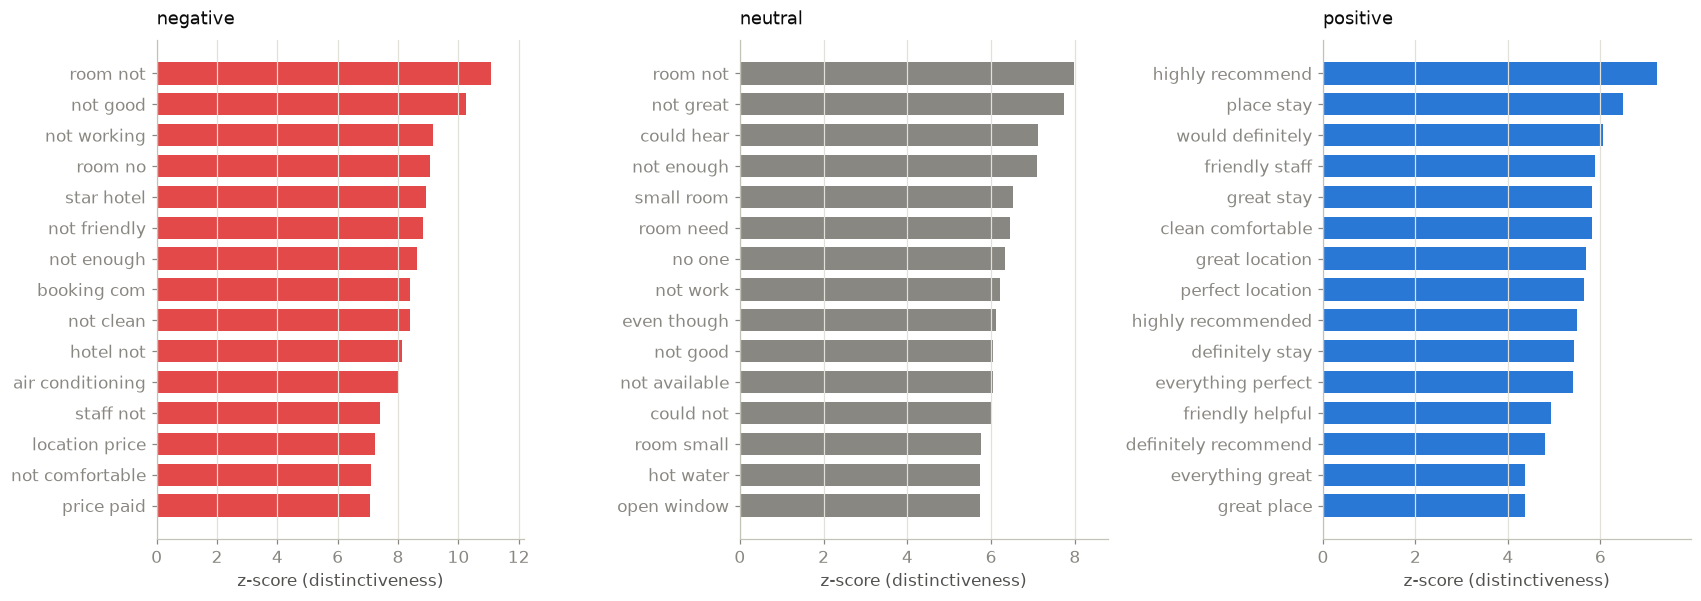

In [2]:
dist_terms = ta.distinctive_terms(data["text_clean"], data[LABEL_COL], ngram_range=(1, 2), top_n=15, min_count=30)
ev.save_table(dist_terms, "04_distinctive_terms")
ta.plot_distinctive_terms(dist_terms, save_as="04_distinctive_terms"); plt.show()

multi = ta.distinctive_terms(data["text_clean"], data[LABEL_COL], ngram_range=(2, 3), top_n=15, min_count=30)
ev.save_table(multi, "04_distinctive_multiword")
ta.plot_distinctive_terms(multi, save_as="04_distinctive_multiword"); plt.show()

16:05:12 | INFO    | src.evaluation | Table saved: 04_frequent_terms.csv


,top_n,shared_by_all_classes,mean_pairwise_jaccard
most frequent (count),15.0,11.0,0.670
most distinctive (z-score),15.0,0.0,0.067


16:05:12 | INFO    | src.evaluation | Table saved: 04_frequent_vs_distinctive_overlap.csv
16:05:14 | INFO    | src.evaluation | Figure saved: 04_frequent_vs_distinctive.png


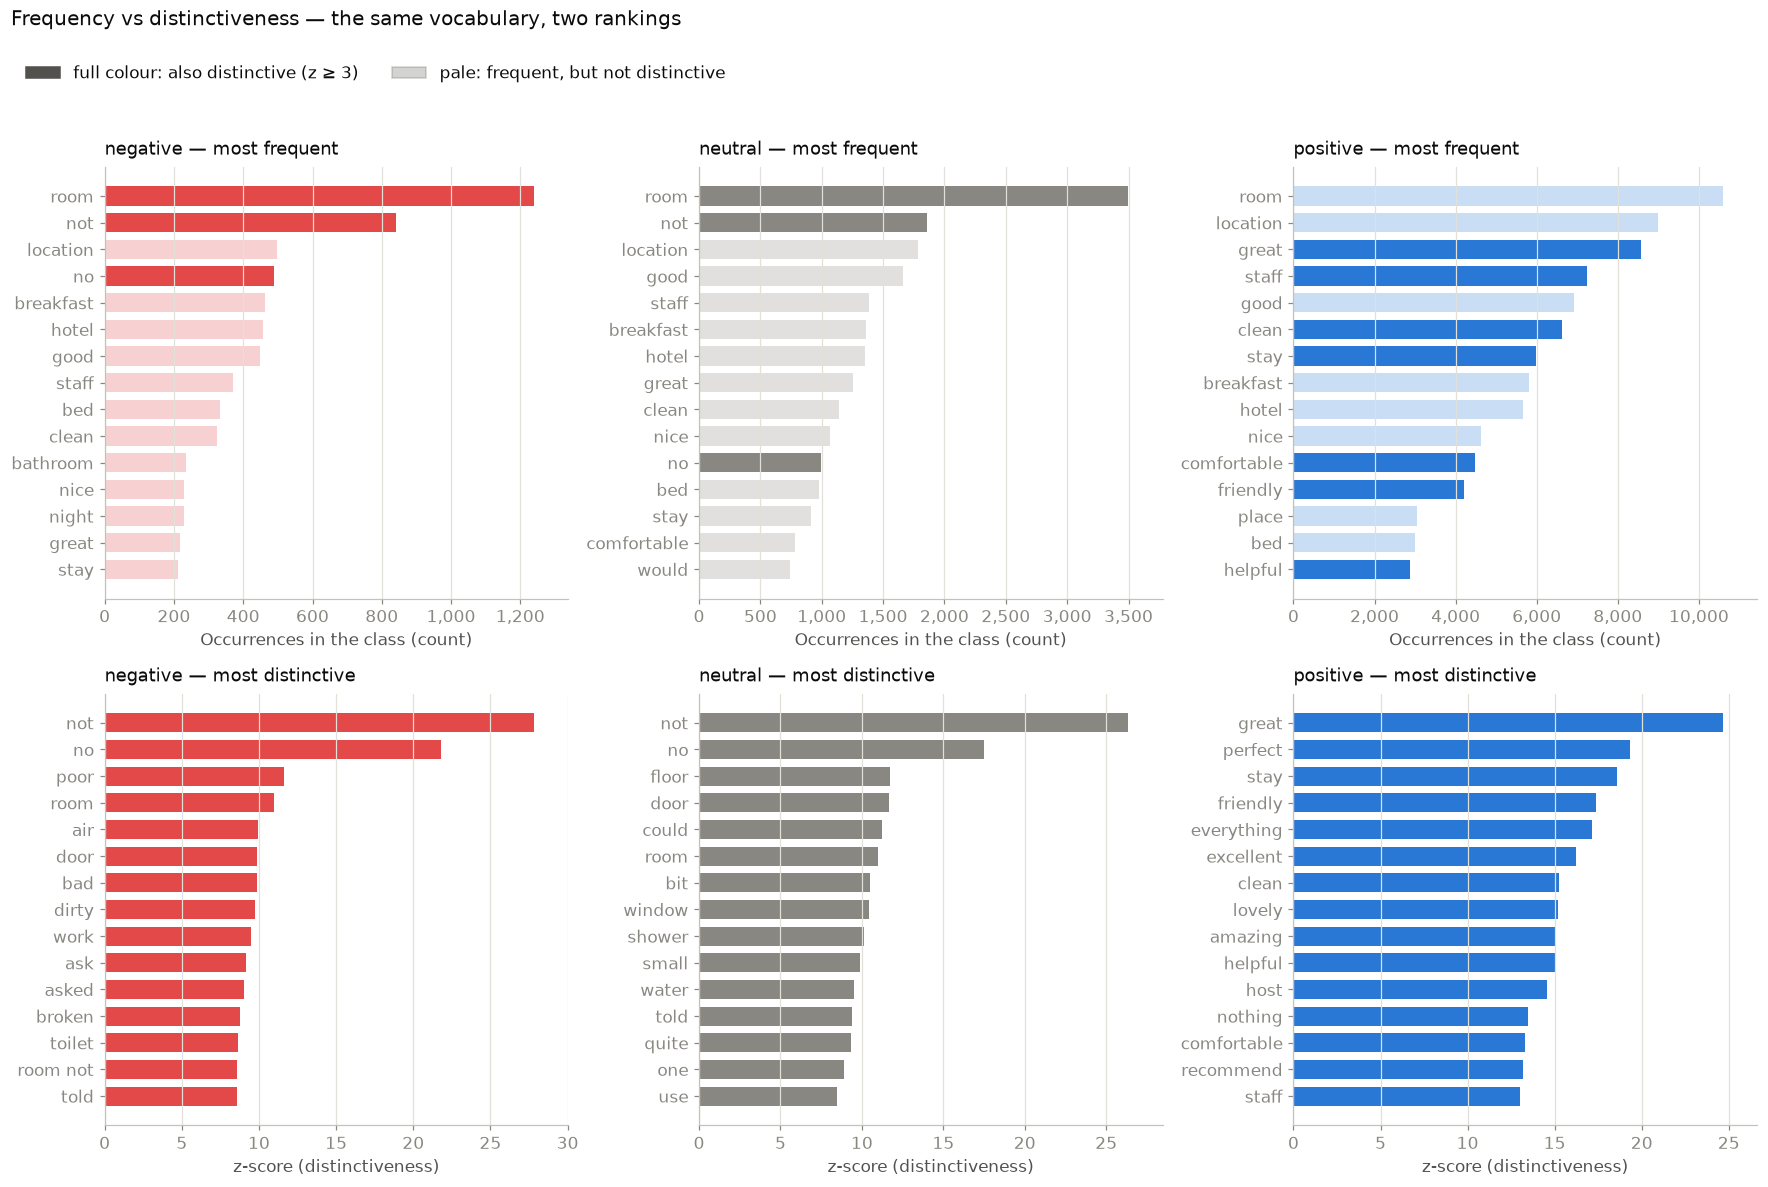

In [3]:
# HU: Gyakoriság vs. megkülönböztető erő — ugyanazon a szókincsen. A naiv gyakorisági lista
#     osztályonként szinte azonos; a z-pontszám mutatja meg, MI különbözteti meg az osztályokat.
# EN: Frequency vs distinctiveness — on the same vocabulary. The naive frequency list is nearly
#     identical across classes; the z-score shows WHAT distinguishes the classes.
freq_terms = ta.top_frequent_terms(data["text_clean"], data[LABEL_COL], ngram_range=(1, 2), top_n=15, min_count=30)
ev.save_table(freq_terms, "04_frequent_terms")
overlap = ta.top_list_overlap(freq_terms, dist_terms, top_n=15)
display(overlap); ev.save_table(overlap, "04_frequent_vs_distinctive_overlap")
ta.plot_frequency_vs_distinctive(freq_terms, dist_terms, top_n=15, save_as="04_frequent_vs_distinctive")
plt.show()

,total,negative,neutral,positive,neg_lift
bigram,,,,,
not clean,78,0.2692,0.3974,0.3333,4.8034
not good,154,0.2338,0.3442,0.4221,4.1707
not working,125,0.2320,0.2960,0.4720,4.1392
not enough,122,0.2213,0.4098,0.3689,3.9485
no one,83,0.2169,0.4337,0.3494,3.8692
not work,85,0.2118,0.4235,0.3647,3.7781
not sure,77,0.2078,0.4026,0.3896,3.7073
not comfortable,98,0.2041,0.3469,0.4490,3.6411
no breakfast,62,0.1774,0.3710,0.4516,3.1654


16:05:15 | INFO    | src.evaluation | Table saved: 04_negation_bigrams.csv


,n (plain),negative share (plain),n (negated),negative share (negated),difference,lift (negated)
word,,,,,,
friendly,4470,0.0168,39,0.4103,0.3935,7.3195
nice,4593,0.0379,25,0.2800,0.2421,4.9955
clean,7142,0.0374,81,0.2593,0.2219,4.6255
comfortable,4750,0.0299,96,0.1979,0.1680,3.5311
good,6406,0.0476,184,0.2011,0.1535,3.5876
hot water,188,0.0851,39,0.2051,0.1200,3.6597
working,257,0.0973,125,0.2160,0.1187,3.8537
great,6966,0.0240,139,0.0935,0.0696,1.6686
big,1066,0.0544,111,0.0721,0.0177,1.2859


16:05:17 | INFO    | src.evaluation | Table saved: 04_negation_effect.csv
16:05:17 | INFO    | src.evaluation | Figure saved: 04_negation_effect.png


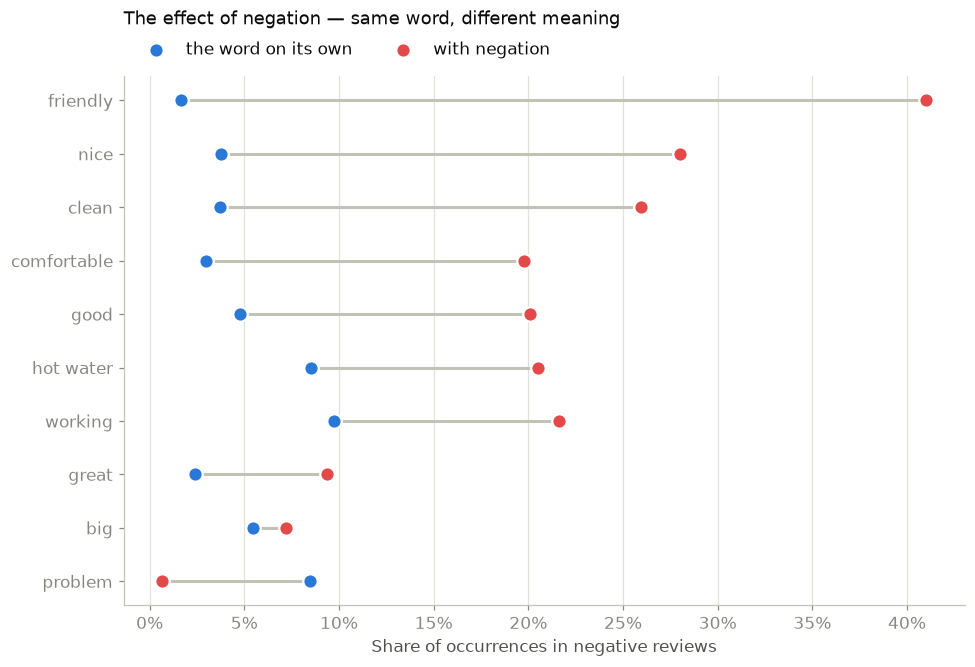

16:05:18 | INFO    | src.text_analysis | Vocabulary: 1664 terms (1-1-gram)
16:05:19 | INFO    | src.text_analysis | Vocabulary: 3083 terms (1-2-gram)
16:05:22 | INFO    | src.text_analysis | Vocabulary: 3292 terms (1-3-gram)


,top-50 mean z,multi-word share in top-50,example (negative)
n-gram level,,,
"unigram (1,1)",9.198,0.000,—
"uni+bigram (1,2)",9.509,0.127,"room not, not good, not friendly"
"uni+bi+trigram (1,3)",9.530,0.127,"room not, not good, not friendly"


16:05:22 | INFO    | src.evaluation | Table saved: 04_ngram_levels.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/04_ngram_levels.csv')

In [4]:
neg_bi = ta.negation_bigrams(data["text_clean"], data[LABEL_COL], min_count=20)
display(neg_bi); ev.save_table(neg_bi, "04_negation_bigrams")

neg_effect = ta.compare_with_without_negation(data["text_clean"], data[LABEL_COL])
display(neg_effect); ev.save_table(neg_effect, "04_negation_effect")
ta.plot_negation_effect(neg_effect, save_as="04_negation_effect"); plt.show()

ngram_cmp = ta.ngram_level_comparison(data["text_clean"], data[LABEL_COL], min_count=30)
display(ngram_cmp); ev.save_table(ngram_cmp, "04_ngram_levels")

## 2. Leíró statisztika és kereszttáblák / Descriptive statistics and crosstabs

In [5]:
overview = ds.dataset_overview(data, label_col=LABEL_COL)
display(overview); ev.save_table(overview, "04_dataset_overview_labelled")

crosstabs = ds.run_all_crosstabs(data, min_count=100, label_col=LABEL_COL)
for col, tab in crosstabs.items():
    print(f"=== {col} ==="); display(tab)

,Value
Metric,
Number of reviews,"20,000"
Unique properties,"4,371"
Number of countries,118
Accommodation types,24
Mean guest score,8.88
Median guest score,9.00
Guest score std,1.15
Mean review length (words),49.3
Median review length (words),37


16:05:22 | INFO    | src.evaluation | Table saved: 04_dataset_overview_labelled.csv
16:05:22 | INFO    | src.evaluation | Table saved: 04_crosstab_accommodation_country.csv
16:05:23 | INFO    | src.evaluation | Figure saved: 04_crosstab_accommodation_country.png
16:05:23 | INFO    | src.evaluation | Table saved: 04_crosstab_accommodation_type.csv
16:05:23 | INFO    | src.evaluation | Figure saved: 04_crosstab_accommodation_type.png
16:05:23 | INFO    | src.evaluation | Table saved: 04_crosstab_guest_type.csv
16:05:23 | INFO    | src.evaluation | Figure saved: 04_crosstab_guest_type.png
16:05:23 | INFO    | src.evaluation | Table saved: 04_crosstab_accommodation_star_rating.csv
16:05:24 | INFO    | src.evaluation | Figure saved: 04_crosstab_accommodation_star_rating.png


=== accommodation_country ===


,n,share,negative,neutral,positive,neg_lift,pos_lift,mean_guest_score,mean_text_score
accommodation_country,,,,,,,,,
United States of America,2369,0.1184,0.0946,0.2005,0.7049,1.6870,0.8923,8.6408,7.7353
Australia,1042,0.0521,0.0605,0.1526,0.7869,1.0787,0.9961,8.6814,8.2284
Spain,874,0.0437,0.0481,0.1659,0.7860,0.8574,0.9949,8.9474,8.2517
United Kingdom,3692,0.1846,0.0471,0.1517,0.8012,0.8408,1.0141,8.7825,8.3229
Portugal,389,0.0194,0.0463,0.1440,0.8098,0.8256,1.0250,8.9692,8.2622
Thailand,536,0.0268,0.0429,0.1735,0.7836,0.7656,0.9918,8.8713,8.2388
New Zealand,403,0.0202,0.0422,0.1365,0.8213,0.7526,1.0396,8.7916,8.3648
Indonesia,389,0.0194,0.0411,0.1337,0.8252,0.7338,1.0445,9.0206,8.3496
France,646,0.0323,0.0402,0.1471,0.8127,0.7181,1.0287,8.7229,8.3142


=== accommodation_type ===


,n,share,negative,neutral,positive,neg_lift,pos_lift,mean_guest_score,mean_text_score
accommodation_type,,,,,,,,,
Resort,753,0.0377,0.0770,0.2165,0.7065,1.3742,0.8943,8.8592,7.7756
Hotel,11358,0.5679,0.0666,0.1658,0.7676,1.1891,0.9715,8.7524,8.1007
Motel,682,0.0341,0.0587,0.1378,0.8035,1.0464,1.0170,8.6364,8.3651
ApartHotel,855,0.0428,0.0573,0.1719,0.7708,1.0225,0.9756,8.8936,8.1287
Hostel,717,0.0358,0.0516,0.1590,0.7894,0.9207,0.9992,8.9107,8.3361
Lodge,138,0.0069,0.0507,0.2029,0.7464,0.9050,0.9447,8.9420,8.1522
Apartment,1739,0.0870,0.0385,0.1346,0.8269,0.6874,1.0467,9.1656,8.4675
Guest house,1363,0.0682,0.0308,0.1189,0.8503,0.5498,1.0763,9.1159,8.6156
Inn,362,0.0181,0.0276,0.1105,0.8619,0.4929,1.0909,8.9190,8.5028


=== guest_type ===


,n,share,negative,neutral,positive,neg_lift,pos_lift,mean_guest_score,mean_text_score
guest_type,,,,,,,,,
Solo traveller,3625,0.1812,0.0654,0.1570,0.7777,1.1664,0.9843,8.7721,8.1763
Family with children,5464,0.2732,0.0653,0.1704,0.7643,1.1657,0.9674,8.8490,8.1149
Group,2430,0.1215,0.0560,0.1383,0.8058,0.9985,1.0199,8.8901,8.3156
Couple,8481,0.4240,0.0461,0.1464,0.8075,0.8225,1.0220,8.9335,8.3266


=== accommodation_star_rating ===


,n,share,negative,neutral,positive,neg_lift,pos_lift,mean_guest_score,mean_text_score
accommodation_star_rating,,,,,,,,,
3,5256,0.2628,0.0691,0.1667,0.7643,1.2322,0.9674,8.7164,8.1056
5,1055,0.0528,0.0673,0.1630,0.7697,1.2007,0.9742,9.0436,8.0919
4.5,137,0.0068,0.0657,0.1460,0.7883,1.1721,0.9978,8.7080,8.2847
2,1166,0.0583,0.0643,0.1818,0.7539,1.1476,0.9542,8.5949,8.0077
4,5689,0.2844,0.0612,0.1619,0.7769,1.0914,0.9834,8.8541,8.1491
3.5,164,0.0082,0.0549,0.1159,0.8293,0.9791,1.0496,8.7256,8.5976
n/a,6384,0.3192,0.0378,0.1322,0.8300,0.6735,1.0506,9.0559,8.4789
1,145,0.0072,0.0345,0.0966,0.8690,0.6152,1.0999,8.9655,8.6621


16:05:24 | INFO    | src.evaluation | Table saved: 04_heatmap_type_x_stars.csv
16:05:25 | INFO    | src.evaluation | Figure saved: 04_heatmap_type_x_stars.png


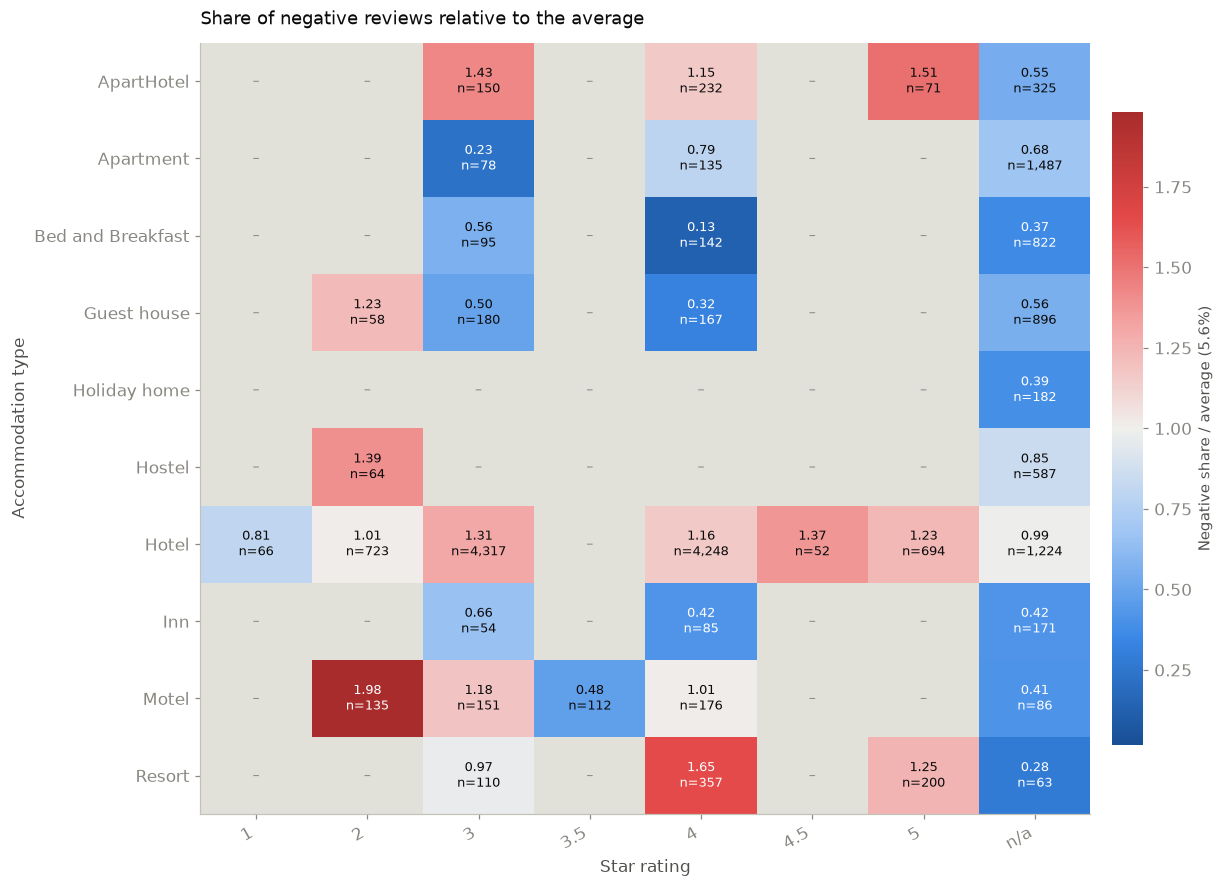

16:05:25 | INFO    | src.evaluation | Table saved: 04_heatmap_country_x_type.csv
16:05:26 | INFO    | src.evaluation | Figure saved: 04_heatmap_country_x_type.png


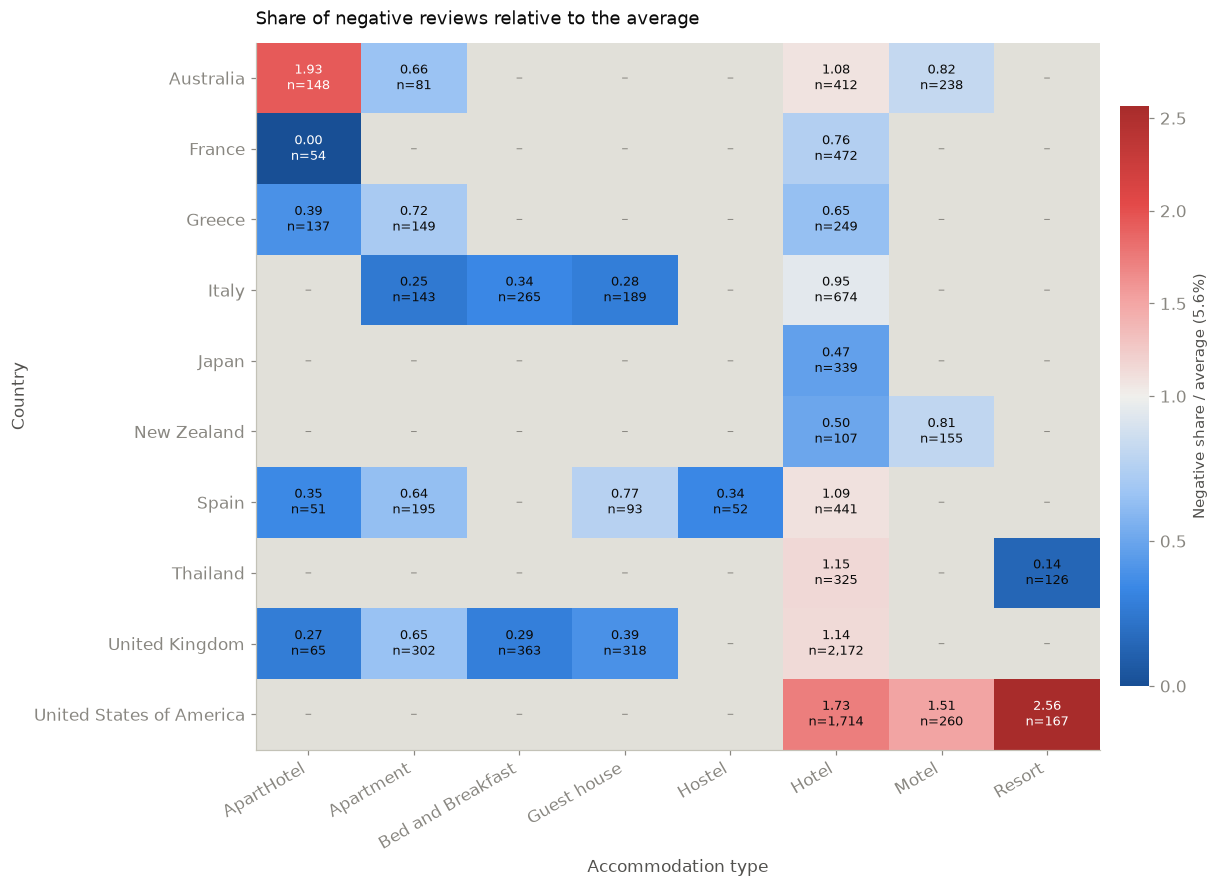

In [6]:
def heatmap(rows, cols, xlabel, ylabel, fname, min_count=50):
    """HU: Hőtérkép hibatűréssel. / EN: Heatmap with fault tolerance."""
    if not {rows, cols} <= set(data.columns):
        return print(f"Skipped — missing column: {rows}, {cols}")
    try:
        lift, counts, base = ds.negativity_heatmap(data, rows, cols, min_count=min_count, label_col=LABEL_COL)
    except ValueError as e:
        return print(f"Skipped: {e}")
    ev.save_table(lift, fname)
    ds.plot_negativity_heatmap(lift, counts, base, "Share of negative reviews relative to the average",
                               xlabel=xlabel, ylabel=ylabel, save_as=fname)
    plt.show()

heatmap("accommodation_type", "accommodation_star_rating", "Star rating", "Accommodation type", "04_heatmap_type_x_stars")
heatmap("accommodation_country", "accommodation_type", "Accommodation type", "Country", "04_heatmap_country_x_type")

## 3. Aspektusok / Aspects

HU: Két mondatszintű forrás: (1) a Booking-mező polaritása (a vendég döntése), (2) ha elérhető, a (B) modell mondatszintű
előrejelzése. A kettő összevetése maga is ellenőrzés.
EN: Two sentence-level sources: (1) the Booking field polarity (the guest's choice), (2) if available, the sentence-level
predictions of model (B). Comparing the two is a check in itself.

16:05:27 | INFO    | src.aspects | Sentences by field polarity: {'positive': 53377, 'negative': 23409}


,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
bathroom,4594,0.0598,0.5250,0.0,0.4750,1.7222,0.6833
wifi,684,0.0089,0.5117,0.0,0.4883,1.6785,0.7025
noise,2756,0.0359,0.3940,0.0,0.6060,1.2926,0.8717
facilities,5799,0.0755,0.3318,0.0,0.6682,1.0883,0.9613
parking,1566,0.0204,0.3276,0.0,0.6724,1.0745,0.9673
room,18598,0.2422,0.3149,0.0,0.6851,1.0328,0.9856
value_for_money,3110,0.0405,0.2910,0.0,0.7090,0.9545,1.0199
pool,2153,0.0280,0.2476,0.0,0.7524,0.8120,1.0824
breakfast,9727,0.1267,0.2121,0.0,0.7879,0.6957,1.1335


16:05:30 | INFO    | src.evaluation | Table saved: 04_aspects_by_field_polarity.csv
16:05:31 | INFO    | src.evaluation | Figure saved: 04_aspects_by_field_polarity.png


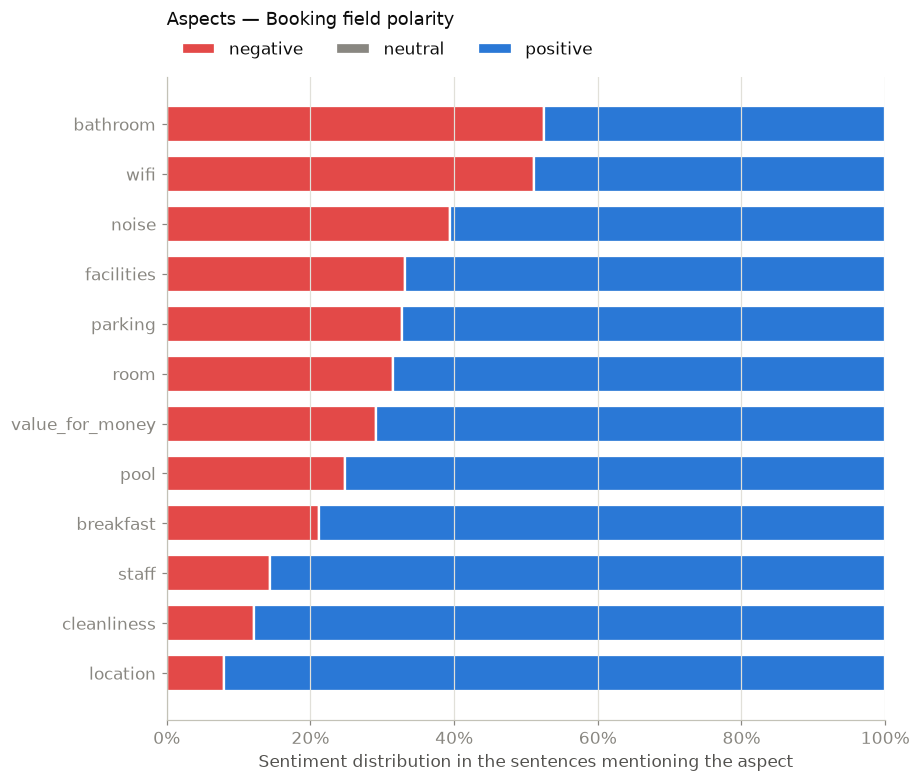

,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
bathroom,4720,0.0525,0.4595,0.0460,0.4945,2.1887,0.6641
wifi,753,0.0084,0.4236,0.0571,0.5193,2.0178,0.6973
noise,3067,0.0341,0.3013,0.0395,0.6593,1.4349,0.8854
facilities,6129,0.0681,0.2819,0.0413,0.6768,1.3429,0.9089
room,19612,0.2180,0.2636,0.0445,0.6919,1.2556,0.9292
parking,1687,0.0188,0.2537,0.0646,0.6817,1.2084,0.9155
pool,2256,0.0251,0.2256,0.0288,0.7456,1.0746,1.0013
value_for_money,4506,0.0501,0.1997,0.0493,0.7510,0.9513,1.0086
breakfast,10453,0.1162,0.1887,0.0445,0.7668,0.8990,1.0297


16:05:35 | INFO    | src.evaluation | Table saved: 04_aspects_by_bert_sentence.csv
16:05:35 | INFO    | src.evaluation | Figure saved: 04_aspects_by_bert_sentence.png


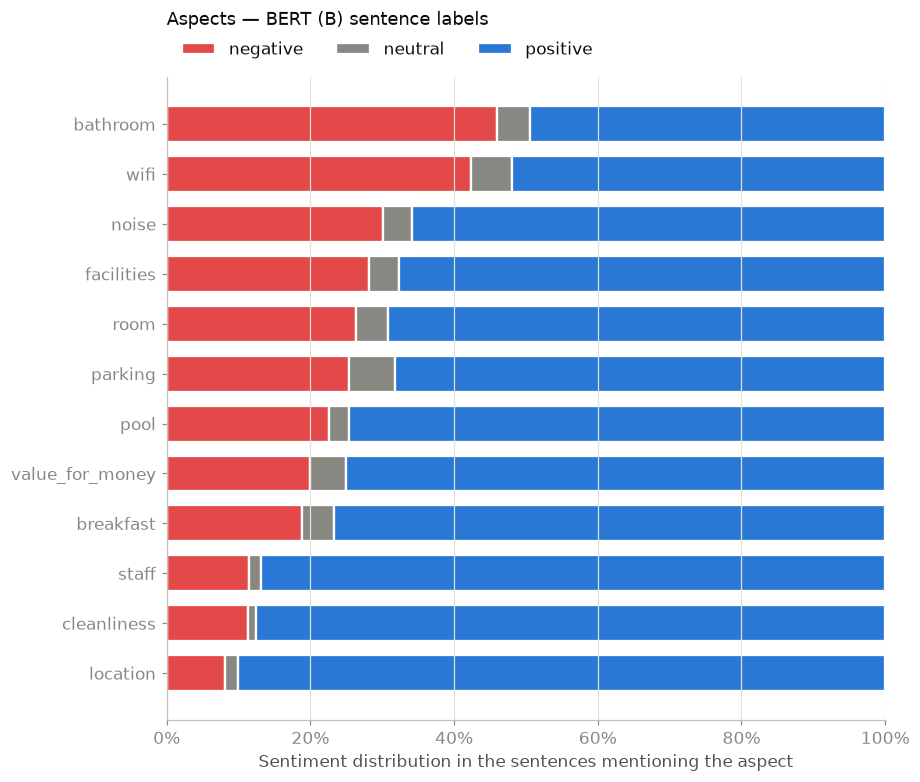

In [7]:
field_sent = asp.add_aspect_columns(asp.explode_by_polarity(data))
aspect_field = asp.aspect_sentiment_table(field_sent, label_col="field_polarity", min_count=50)
display(aspect_field); ev.save_table(aspect_field, "04_aspects_by_field_polarity")
asp.plot_aspect_sentiment(aspect_field, "Aspects — Booking field polarity", save_as="04_aspects_by_field_polarity")
plt.show()

if dl.frame_exists(PATHS.labels / "sentences_B"):
    sent_b = asp.add_aspect_columns(dl.read_frame(PATHS.labels / "sentences_B"))
    aspect_b = asp.aspect_sentiment_table(sent_b, label_col="B_label", min_count=50)
    display(aspect_b); ev.save_table(aspect_b, "04_aspects_by_bert_sentence")
    asp.plot_aspect_sentiment(aspect_b, "Aspects — BERT (B) sentence labels", save_as="04_aspects_by_bert_sentence")
    plt.show()

## 4. Klasszikus "tanítvány" modellek / Classical "student" models

HU: A mért pontosság itt a **BERT-címkékkel való egyezés** (tudásdesztilláció). A valódi pontosságot a gold mintán
mérjük (5. pont). `TRAIN_ON_UNANIMOUS=True`: csak az egybehangzó (legbiztosabb) címkéken tanít.
EN: The measured accuracy here is **agreement with the BERT labels** (knowledge distillation). True accuracy is measured
on the gold sample (section 5). `TRAIN_ON_UNANIMOUS=True`: trains only on the unanimous (most reliable) labels.

In [8]:
TRAIN_ON_UNANIMOUS = False
# HU: A gold minta véleményei NEM kerülhetnek a tanítóhalmazba, különben az 5. pont gold-összevetése
#     nem lenne független (a modell látta volna ezeket a szövegeket a (B)-címkével).
# EN: The gold-sample reviews must NOT be in the training data, otherwise the gold comparison in
#     section 5 would not be independent (the model would have seen these texts with the (B) label).
gold_ids = set(lv.load_gold().index) if (PATHS.annotation / "gold_sample_to_annotate.csv").exists() else set()
model_data = data[~data["review_id"].isin(gold_ids)]
print(f"Excluded gold reviews from model training: {len(data) - len(model_data)}")
train_df, val_df, test_df = pp.train_val_test_split(model_data, label_col=LABEL_COL)
if TRAIN_ON_UNANIMOUS and "unanimous" in train_df:
    train_df = train_df[train_df["unanimous"]]

display(ev.baseline_metrics(test_df[LABEL_COL]))

t0 = time.time()
summary, fitted = mc.train_and_evaluate_all(train_df, val_df, label_col=LABEL_COL)
print(f"Training time: {time.time() - t0:.1f} s")
display(summary[["accuracy", "f1_macro", "f1_weighted", "n_features"]].round(4))
ev.save_table(summary, "04_classical_validation")

16:05:35 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
16:05:35 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
16:05:36 | INFO    | src.preprocessing | Split — train: 11760 | val: 3920 | test: 3921


Excluded gold reviews from model training: 399


,accuracy,f1_macro,f1_weighted
baseline,,,
majority class ('positive'),0.7906,0.2944,0.6982
stratified random,0.6516,0.3423,0.6530
uniform random,0.3349,0.2618,0.4097


16:05:36 | INFO    | src.models_classical | Training: nb (11760 samples)
16:05:37 | INFO    | src.models_classical | Model saved: tfidf_nb_label_final.joblib
16:05:37 | INFO    | src.models_classical | Training: logreg (11760 samples)
16:05:39 | INFO    | src.models_classical | Model saved: tfidf_logreg_label_final.joblib
16:05:39 | INFO    | src.models_classical | Training: svm (11760 samples)
16:05:40 | INFO    | src.models_classical | Model saved: tfidf_svm_label_final.joblib


Training time: 4.4 s


,accuracy,f1_macro,f1_weighted,n_features
model,,,,
logreg,0.7663,0.5534,0.7850,21062
svm,0.7980,0.5230,0.7909,21062
nb,0.7954,0.3168,0.7120,21062


16:05:40 | INFO    | src.evaluation | Table saved: 04_classical_validation.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/04_classical_validation.csv')

Best on validation: logreg


,precision,recall,f1-score,support
negative,0.337,0.416,0.372,219.000
neutral,0.372,0.497,0.426,602.000
positive,0.918,0.844,0.879,3100.000
accuracy,0.766,0.766,0.766,0.766
macro avg,0.543,0.585,0.559,3921.000
weighted avg,0.802,0.766,0.781,3921.000


16:05:41 | INFO    | src.evaluation | Figure saved: 04_confusion_matrices_classical.png


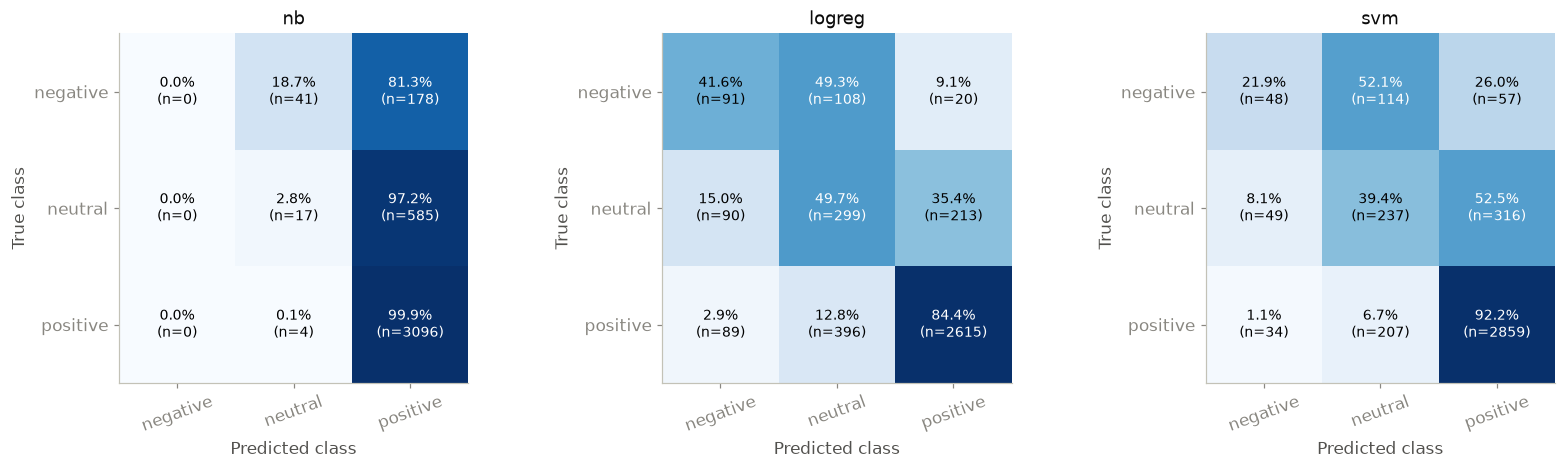

In [9]:
best_name = summary.index[0]
y_true = test_df[LABEL_COL].astype(str)
y_pred = fitted[best_name].predict(test_df["text_clean"])
print(f"Best on validation: {best_name}")
display(ev.per_class_report(y_true, y_pred).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, name in zip(axes, mc.MODEL_NAMES):
    ev.plot_confusion_matrix(y_true, fitted[name].predict(test_df["text_clean"]), title=name, ax=ax)
plt.tight_layout(); ev.save_figure("04_confusion_matrices_classical"); plt.show()

In [10]:
# HU: Ablációs vizsgálat mintán (8 változat). / EN: Ablation study on a sample (8 variants).
abl_train = train_df.sample(min(20_000, len(train_df)), random_state=CFG.random_seed)
ablation = mc.preprocessing_ablation(abl_train, val_df, label_col=LABEL_COL)
display(ablation[["accuracy", "f1_macro", "n_features"]].round(4))
ev.save_table(ablation, "04_preprocessing_ablation")

16:05:47 | INFO    | src.models_classical | raw text, unigram                    macro-F1 = 0.5557
16:05:49 | INFO    | src.models_classical | raw text, uni+bigram                 macro-F1 = 0.5709
16:05:50 | INFO    | src.models_classical | full cleaning, unigram               macro-F1 = 0.5371
16:05:51 | INFO    | src.models_classical | full cleaning, uni+bigram            macro-F1 = 0.5534
16:05:54 | INFO    | src.models_classical | full cleaning, uni+bi+trigram        macro-F1 = 0.5568
16:05:55 | INFO    | src.models_classical | full cleaning, sublinear_tf off      macro-F1 = 0.5592
16:05:57 | INFO    | src.models_classical | full cleaning, max_features=10k      macro-F1 = 0.5568
16:05:58 | INFO    | src.models_classical | cleaning, negation words dropped     macro-F1 = 0.5372


,accuracy,f1_macro,n_features
variant,,,
"raw text, uni+bigram",0.7796,0.5709,31681
"full cleaning, sublinear_tf off",0.7684,0.5592,21062
"full cleaning, uni+bi+trigram",0.7707,0.5568,26833
"full cleaning, max_features=10k",0.7628,0.5568,10000
"raw text, unigram",0.7520,0.5557,5755
"full cleaning, uni+bigram",0.7663,0.5534,21062
"cleaning, negation words dropped",0.7597,0.5372,20591
"full cleaning, unigram",0.7413,0.5371,4981


16:05:58 | INFO    | src.evaluation | Table saved: 04_preprocessing_ablation.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/04_preprocessing_ablation.csv')

16:05:58 | INFO    | src.evaluation | Table saved: 04_top_features_logreg.csv
16:05:59 | INFO    | src.evaluation | Figure saved: 04_top_features_logreg.png


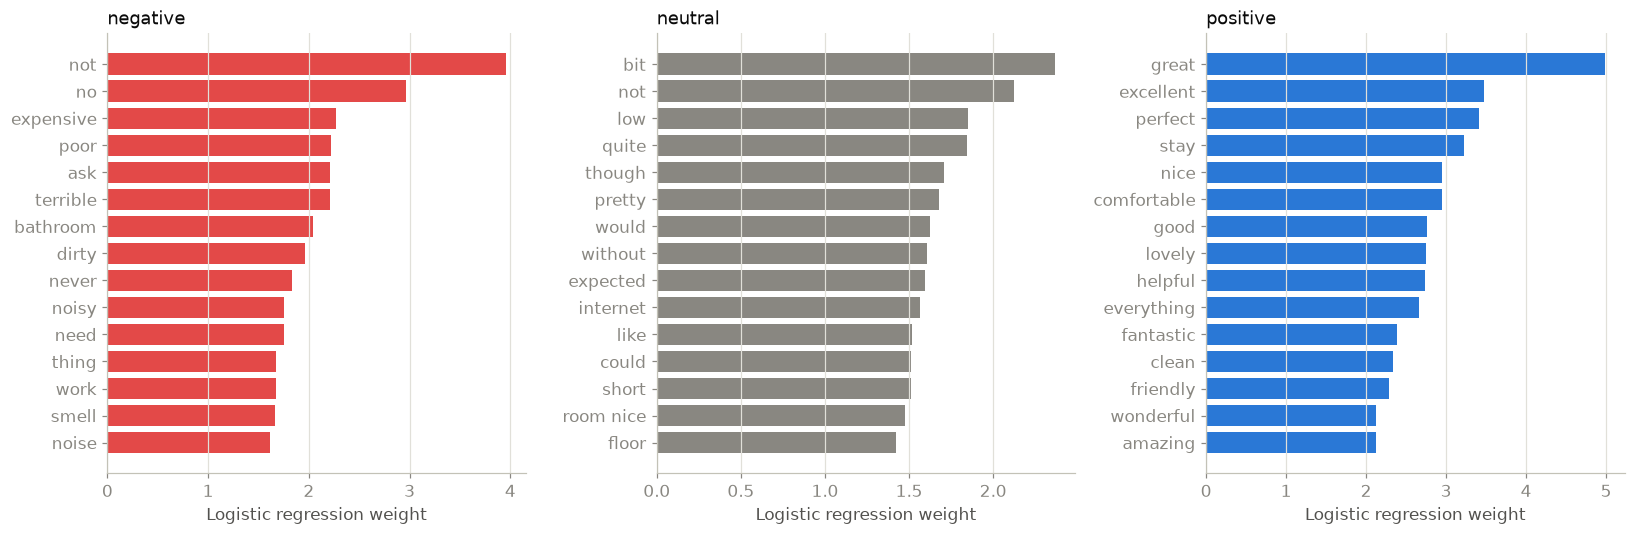

16:05:59 | INFO    | src.evaluation | Errors: 916 / 3921 (23.4%)
16:05:59 | INFO    | src.evaluation | Table saved: 04_error_examples.csv


,error_type,true,predicted,score,text
0,negative -> neutral,negative,neutral,8.0,disappointed that the restaurant was not open for the two days of our stay. breakfast was as we expected but in a lo...
1,negative -> neutral,negative,neutral,8.0,Only stayed one night and would stay there again. Location was nice. Breakfast was ok though could have been warmer ...
2,negative -> neutral,negative,neutral,8.0,Short stay in HK. No breakfast. Near flower market and ladies market Central Next to MTR station Near MOKO shopping ...
3,negative -> neutral,negative,neutral,7.0,"So so but won't come back again. Good location, nearby lots of eateries Hard to locate as it's in between the alley ..."
4,negative -> neutral,negative,neutral,6.0,"Tolerable for one night stay, over priced for the condition. Good location, breakfast good enough, good shower press..."
5,negative -> positive,negative,positive,10.0,The location on the cliff overlooking the Pacific Ocean The small little town essentially shuts down at 5:00 p.m.
6,negative -> positive,negative,positive,7.0,"Hotel was fine, great location and breakfast but too expensive even if there was a large conference. Breakfast and s..."
7,negative -> positive,negative,positive,10.0,Room shower I was able to book the same kind of suite they jcer by bower for 1/4 of the price and its much nicer was...
8,negative -> positive,negative,positive,7.0,Overall not a bad place to stay. Needs some improvement though. The room and bathroom was clean. The beds were comfo...
9,negative -> positive,negative,positive,8.0,Breakfast was very simple.


In [11]:
top = mc.top_features_per_class(fitted["logreg"], top_n=15)
ev.save_table(top, "04_top_features_logreg")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, label in zip(axes, CFG.labels):
    sub = top[top["sentiment"] == label].sort_values("weight")
    ax.barh(sub["feature"], sub["weight"], color=SENTIMENT_COLORS[label])
    ax.set_title(label, loc="left"); ax.set_xlabel("Logistic regression weight")
    ax.grid(axis="y", visible=False)
plt.tight_layout(); ev.save_figure("04_top_features_logreg"); plt.show()

errors = ev.error_analysis(test_df, y_pred, label_col=LABEL_COL, n_examples=5)
ev.save_table(errors, "04_error_examples")
errors.head(10)

## 5. Összevetés a gold mintán / Comparison on the gold sample

In [12]:
gold_file = PATHS.annotation / "gold_sample_to_annotate.csv"
if gold_file.exists() and len(lv.load_gold()):
    gold = lv.load_gold()
    gold_data = data.set_index("review_id").loc[lambda d: d.index.isin(gold.index)].copy()
    gold_data[f"tfidf_{best_name}"] = fitted[best_name].predict(gold_data["text_clean"])
    sources = {"BERT final": "label_final", f"TF-IDF {best_name}": f"tfidf_{best_name}"}
    comparison = lv.evaluate_on_gold(gold, gold_data, sources)
    display(comparison); ev.save_table(comparison, "04_gold_bert_vs_tfidf")
else:
    print("No annotated gold sample yet (see notebook 03, section 5).")

16:05:59 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
16:05:59 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
16:05:59 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
16:05:59 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
16:05:59 | INFO    | src.label_validation | Gold reviews matched with labels: 399


,n,accuracy,f1_macro,cohen_kappa
source,,,,
BERT final,399,0.8045,0.6405,0.5046
TF-IDF logreg,399,0.7769,0.5749,0.4624


16:05:59 | INFO    | src.evaluation | Table saved: 04_gold_bert_vs_tfidf.csv
